# Практическая работа 8.1. Подготовка датасета

В notebook скачивается датасет с Kaggle, показывается его разбиение и создается prepared-набор данных для обучения модели в PyTorch.


## Импорты


In [1]:
from __future__ import annotations

import os
import shutil
from pathlib import Path

PRACTICE_DIR = Path.cwd()
CACHE_DIR = PRACTICE_DIR / ".cache"
DATA_DIR = PRACTICE_DIR / ".data"
MPL_CACHE_DIR = CACHE_DIR / "matplotlib"
SOURCE_DATASET_DIR = DATA_DIR / "donkeys-horses-zebra-source"
PREPARED_DATASET_DIR = DATA_DIR / "donkeys-horses-zebra-prepared"

for directory in (CACHE_DIR, DATA_DIR, MPL_CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

os.environ["MPLCONFIGDIR"] = str(MPL_CACHE_DIR)


In [2]:
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

DATASET_HANDLE = "ifeanyinneji/donkeys-horses-zebra-images-dataset"
SEED = 42
VALIDATION_FRACTION = 0.2
SPLIT_DIRS = {
    "train": SOURCE_DATASET_DIR / "train",
    "test": SOURCE_DATASET_DIR / "test",
}
CLASS_NAMES = ["horse", "zebra"]
IMAGE_SUFFIXES = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

plt.style.use("seaborn-v0_8-whitegrid")


/Users/mikhail/Developer/SUSU.PE/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Описание данных

В работе используется датасет `Donkeys, Horses & Zebra Images Dataset`:
[https://www.kaggle.com/datasets/ifeanyinneji/donkeys-horses-zebra-images-dataset](https://www.kaggle.com/datasets/ifeanyinneji/donkeys-horses-zebra-images-dataset)

В датасете используются два класса:

- `horse`
- `zebra`

Исходный набор уже разбит на `train` и `test`. Для более корректного обучения из исходного `train` выделяется выборка `val`, а `test` сохраняется без изменений для финальной оценки модели.


## Загрузка датасета


In [3]:
def download_dataset_if_needed(
    source_dataset_dir: Path,
    split_dirs: dict[str, Path],
    dataset_handle: str,
) -> None:
    """
    Скачивает датасет Kaggle, если локальная копия еще не подготовлена.

    Parameters
    ----------
    source_dataset_dir : Path
        Каталог для скачивания датасета.
    split_dirs : dict[str, Path]
        Пути к каталогам train и test.
    dataset_handle : str
        Идентификатор датасета на Kaggle.
    """
    if all(split_dir.is_dir() for split_dir in split_dirs.values()):
        return

    kagglehub.dataset_download(
        dataset_handle,
        output_dir=str(source_dataset_dir),
    )


In [4]:
def collect_split_records(
    split_dirs: dict[str, Path],
    class_names: list[str],
    image_suffixes: tuple[str, ...],
) -> dict[str, dict[str, list[Path]]]:
    """
    Собирает пути к изображениям по классам и исходным split.

    Parameters
    ----------
    split_dirs : dict[str, Path]
        Пути к каталогам train и test.
    class_names : list[str]
        Названия классов.
    image_suffixes : tuple[str, ...]
        Допустимые расширения файлов.

    Returns
    -------
    dict[str, dict[str, list[Path]]]
        Пути к изображениям по split и классам.
    """
    split_records: dict[str, dict[str, list[Path]]] = {}

    for split_name, split_dir in split_dirs.items():
        if not split_dir.is_dir():
            raise FileNotFoundError(f"Не найдена папка split: {split_dir}")

        split_records[split_name] = {}
        for class_name in class_names:
            class_dir = split_dir / class_name
            if not class_dir.is_dir():
                raise FileNotFoundError(f"Не найдена папка класса: {class_dir}")

            image_paths = sorted(
                path for path in class_dir.iterdir()
                if path.is_file() and path.suffix.lower() in image_suffixes
            )
            if not image_paths:
                raise FileNotFoundError(f"В папке {class_dir} не найдены изображения.")

            split_records[split_name][class_name] = image_paths

    return split_records


In [5]:
download_dataset_if_needed(
    SOURCE_DATASET_DIR,
    SPLIT_DIRS,
    DATASET_HANDLE,
)

split_records = collect_split_records(
    SPLIT_DIRS,
    CLASS_NAMES,
    IMAGE_SUFFIXES,
)


## Обзор данных


In [6]:
source_split_class_counts = {
    split_name: {
        class_name: len(paths)
        for class_name, paths in class_records.items()
    }
    for split_name, class_records in split_records.items()
}
source_split_sizes = {
    split_name: sum(class_counts.values())
    for split_name, class_counts in source_split_class_counts.items()
}

print("Классы:", CLASS_NAMES)
for split_name, class_counts in source_split_class_counts.items():
    print(f"\n{split_name}:")
    for class_name, count in class_counts.items():
        print(f"  {class_name}: {count}")
    print(f"  total: {source_split_sizes[split_name]}")


Классы: ['horse', 'zebra']

train:
  horse: 384
  zebra: 234
  total: 618

test:
  horse: 96
  zebra: 60
  total: 156


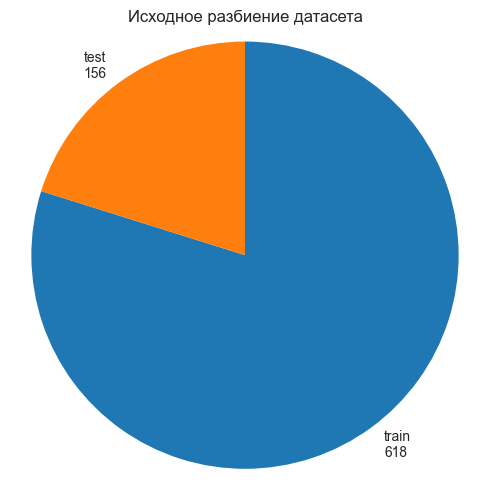

In [7]:
fig, axis = plt.subplots(figsize=(5, 5))
axis.pie(
    list(source_split_sizes.values()),
    labels=[f"{name}\n{size}" for name, size in source_split_sizes.items()],
    startangle=90,
    counterclock=False,
)
axis.set_title("Исходное разбиение датасета")
axis.axis("equal")
plt.tight_layout()
plt.show()


In [8]:
def plot_class_counts(counts: dict[str, int], title: str) -> None:
    """
    Строит диаграмму количества изображений по классам.

    Parameters
    ----------
    counts : dict[str, int]
        Количество изображений по классам.
    title : str
        Заголовок диаграммы.
    """
    fig, axis = plt.subplots(figsize=(7, 4))
    axis.bar(counts.keys(), counts.values(), color=["#8dd3c7", "#80b1d3"])
    axis.set_title(title)
    axis.set_ylabel("Количество изображений")
    plt.tight_layout()
    plt.show()


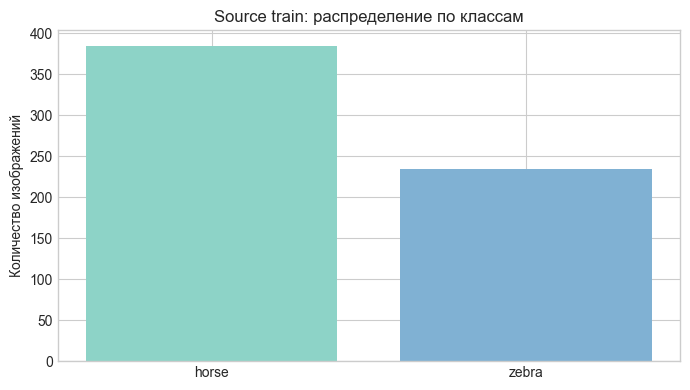

In [9]:
plot_class_counts(source_split_class_counts["train"], "Source train: распределение по классам")


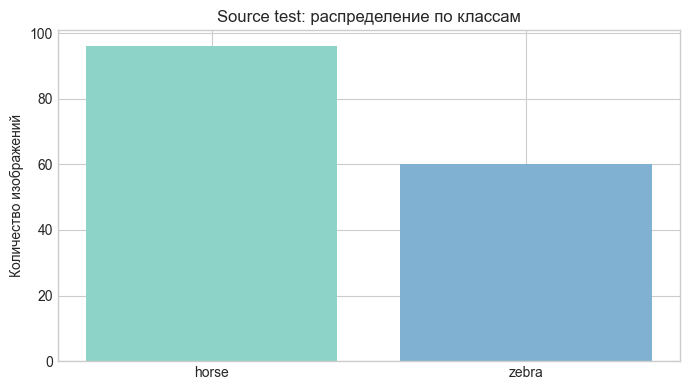

In [10]:
plot_class_counts(source_split_class_counts["test"], "Source test: распределение по классам")


## Превью изображений


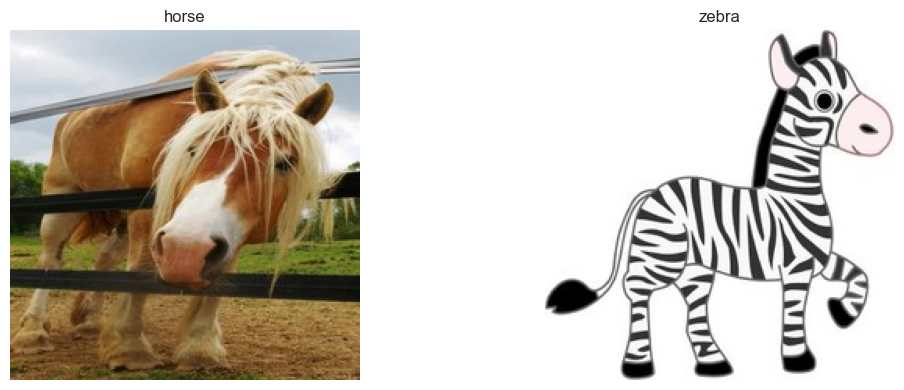

In [11]:
preview_records = [
    (class_name, split_records["train"][class_name][0])
    for class_name in CLASS_NAMES
]

plt.figure(figsize=(12, 4))
for index, (class_name, image_path) in enumerate(preview_records, start=1):
    image = Image.open(image_path).convert("RGB")
    axis = plt.subplot(1, len(preview_records), index)
    axis.imshow(np.asarray(image))
    axis.set_title(class_name)
    axis.axis("off")
plt.tight_layout()
plt.show()


## Подготовка разбиения train / val / test


In [12]:
def make_prepared_split_records(
    split_records: dict[str, dict[str, list[Path]]],
    validation_fraction: float,
    seed: int,
) -> dict[str, dict[str, list[Path]]]:
    """
    Разбивает исходный train на train и val, а test сохраняет без изменений.

    Parameters
    ----------
    split_records : dict[str, dict[str, list[Path]]]
        Исходные пути к изображениям по split и классам.
    validation_fraction : float
        Доля изображений, выделяемая на validation из исходного train.
    seed : int
        Значение для воспроизводимого перемешивания.

    Returns
    -------
    dict[str, dict[str, list[Path]]]
        Пути к изображениям по prepared split и классам.
    """
    rng = np.random.default_rng(seed)
    prepared_split_records = {
        "train": {},
        "val": {},
        "test": {},
    }

    for class_name in CLASS_NAMES:
        train_paths = list(split_records["train"][class_name])
        rng.shuffle(train_paths)

        validation_count = int(len(train_paths) * validation_fraction)
        prepared_split_records["val"][class_name] = train_paths[:validation_count]
        prepared_split_records["train"][class_name] = train_paths[validation_count:]
        prepared_split_records["test"][class_name] = list(split_records["test"][class_name])

    return prepared_split_records


In [13]:
prepared_split_records = make_prepared_split_records(
    split_records,
    VALIDATION_FRACTION,
    SEED,
)

prepared_split_class_counts = {
    split_name: {
        class_name: len(paths)
        for class_name, paths in class_records.items()
    }
    for split_name, class_records in prepared_split_records.items()
}
prepared_split_sizes = {
    split_name: sum(class_counts.values())
    for split_name, class_counts in prepared_split_class_counts.items()
}

for split_name, class_counts in prepared_split_class_counts.items():
    print(f"\n{split_name}:")
    for class_name, count in class_counts.items():
        print(f"  {class_name}: {count}")
    print(f"  total: {prepared_split_sizes[split_name]}")



train:
  horse: 308
  zebra: 188
  total: 496

val:
  horse: 76
  zebra: 46
  total: 122

test:
  horse: 96
  zebra: 60
  total: 156


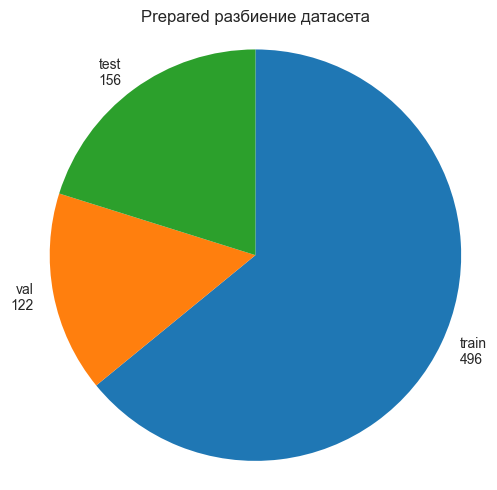

In [14]:
fig, axis = plt.subplots(figsize=(5, 5))
axis.pie(
    list(prepared_split_sizes.values()),
    labels=[f"{name}\n{size}" for name, size in prepared_split_sizes.items()],
    startangle=90,
    counterclock=False,
)
axis.set_title("Prepared разбиение датасета")
axis.axis("equal")
plt.tight_layout()
plt.show()


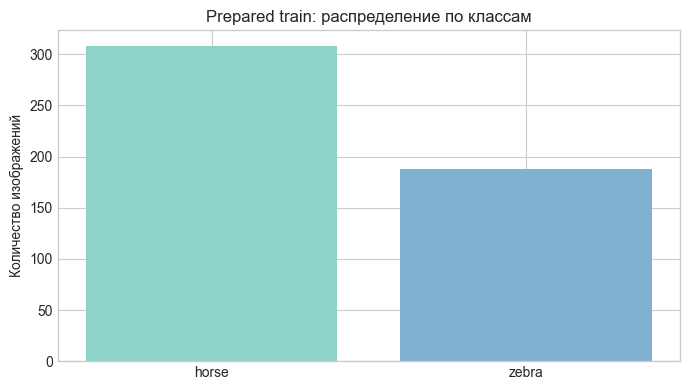

In [15]:
plot_class_counts(prepared_split_class_counts["train"], "Prepared train: распределение по классам")


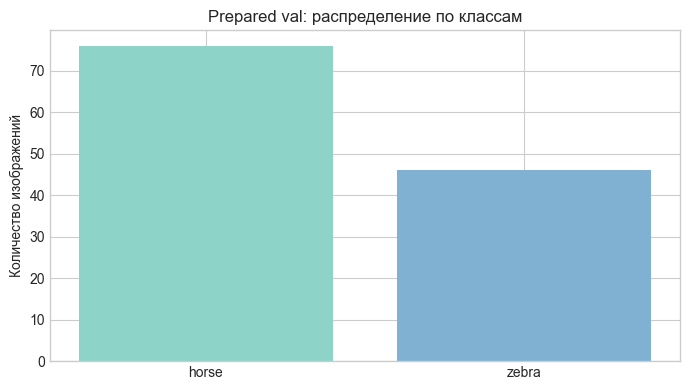

In [16]:
plot_class_counts(prepared_split_class_counts["val"], "Prepared val: распределение по классам")


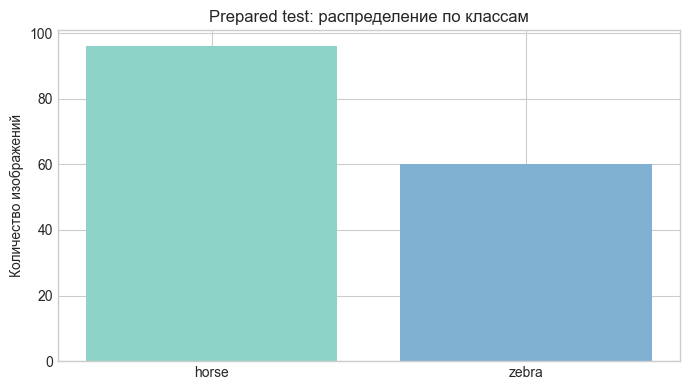

In [17]:
plot_class_counts(prepared_split_class_counts["test"], "Prepared test: распределение по классам")


## Создание prepared-датасета


In [18]:
def create_prepared_dataset(
    split_records: dict[str, dict[str, list[Path]]],
    prepared_dataset_dir: Path,
) -> None:
    """
    Перепаковывает train, val и test в локальный prepared-датасет.

    Parameters
    ----------
    split_records : dict[str, dict[str, list[Path]]]
        Пути к изображениям по split и классам.
    prepared_dataset_dir : Path
        Каталог prepared-датасета.
    """
    if prepared_dataset_dir.exists():
        shutil.rmtree(prepared_dataset_dir)

    for split_name, class_records in split_records.items():
        for class_name, image_paths in class_records.items():
            class_dir = prepared_dataset_dir / split_name / class_name
            class_dir.mkdir(parents=True, exist_ok=True)

            for image_path in image_paths:
                destination_path = class_dir / image_path.name
                shutil.copy2(image_path, destination_path)


In [19]:
create_prepared_dataset(
    prepared_split_records,
    PREPARED_DATASET_DIR,
)

print(PREPARED_DATASET_DIR)


/Users/mikhail/Developer/SUSU.PE/СП-М-О-КЗ-2025/Практика/Практика 8 - Сверточные нейронные сети/.data/donkeys-horses-zebra-prepared


In [20]:
for split_name in ("train", "val", "test"):
    split_root = PREPARED_DATASET_DIR / split_name
    print(f"\n{split_name}:")
    for class_name in CLASS_NAMES:
        class_count = len([path for path in (split_root / class_name).iterdir() if path.is_file()])
        print(f"  {class_name}: {class_count}")



train:
  horse: 308
  zebra: 188

val:
  horse: 76
  zebra: 46

test:
  horse: 96
  zebra: 60
